# Stazioni Monitoraggio ARPA Puglia 

I dati raccolti da ARPA sulla concentrazione dell'alga Ostreopis ovata provengono da due reti di monitoraggio della Puglia differenti, la prima ha raccolto dati sulla densità della microalga, mentre la seconda ha monitorato i parametri chimico-fisici delle acque

Visualizziamo geograficamente le posizioni di queste stazioni sulla cartina 

In [32]:
#installo librerie utili per la visualizzazione dati
!pip install seaborn
!pip install adjustText


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [33]:
# Importazione delle librerie necessarie
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns


In [34]:
# Caricamento del dataset delle stazioni ARPA in cui sono stati presi parametri chimico-fisici delle acque
file_excel = "C:\\Users\\sofia\\Università\\Tirocinio\\Dati ARPA\\Arpa_Puglia_dataset\\Dataset_CIS-Aliena-2014-2023.xlsx"
#pd.read_excel() legge il file excel e lo salva in un dataframe 
df_cis = pd.read_excel(file_excel, header=2)  #header=2, indica quale riga della tabella Excel usare come intestazione per i nomi delle colonne (il conteggio parte sempre da 0)
#rinomino le colonne del dataframe 
df_cis.columns = ['Corpo_idrico', 'Descrizione', 'Code_staz', 'LAT_DMS', 'LONG_DMS']
#non posso usare direttamente la funzione dropna() per rimuovere i valori nulli perchè la prima colonna (Corpo_idrico) è compilata solo per la prima riga di ciascun gruppo (è una cella unita, che però python non riconosce)
    #quindi riempiamo i valori vuoti con ffill() che riempie le celle vuote/unite con l'ultimo valore valido della colonna 
df_cis['Corpo_idrico'] = df_cis['Corpo_idrico'].ffill()
# visualizzazione del df come una tabella  
display(df_cis)


,Corpo_idrico,Descrizione,Code_staz,LAT_DMS,LONG_DMS
0,Torre Canne-Limite nord AMP Torre Guaceto,Villanova_500,MC_VL01,"40°47' 44,300"" N","17°35' 31,200"" E"
1,Torre Canne-Limite nord AMP Torre Guaceto,Villanova_1750,MC_VL02,"40°48' 24,478"" N","17°35' 55,524"" E"
2,Area Marina Protetta Torre Guaceto,T_Guaceto_500,MC_TG01,"40°42' 29,400"" N","17°48' 40,900"" E"
3,Area Marina Protetta Torre Guaceto,T_Guaceto_1750,MC_TG02,"40°43' 24,701"" N","17°49' 29,575"" E"
4,Limite sud AMP Torre Guaceto-Brindisi,P_Penne_100,MC_PP01,"40°41' 10,983"" N","17°56' 22,482"" E"
5,Limite sud AMP Torre Guaceto-Brindisi,P_Penne_600,MC_PP02,"40°41' 22,300"" N","17°56' 27,654"" E"
6,Brindisi-Cerano,BR_CapoBianco_500,MC_CB01,"40°38' 59,200"" N","18°0' 19,500"" E"
7,Brindisi-Cerano,BR_CapoBianco_1750,MC_CB02,"40°39' 53,765"" N","18°1' 10,542"" E"


## Conversione delle coordinate geografiche da DMS a numeri decimali (DD)

Per poter tracciare le stazioni di monitoraggio in un grafico tramite librerie come *Matlotlib* e *Seaborn* le coordinate spaziali devono essere espresse come numeri reali (*float*)

Nel dataset originale la Latitudine e la Longitudine sono memorizzare nel sistema sessagesimale DMS (Gradi, Minuti, Secondi -- es. 40°59'10"N) essendo espresse tramite simboli e lettere (°, ', ", N, E) Python le interpreta come stringhe testuali anzichè valori testuali

E'pertanto necessario innanzitutto trasformarli in valori numerici e sucessivamente convertirli nel sistema decimale

1. Estrazione dei valori con il **modulo re** (*Regular Expression*)
    re permette di definire un pattern di ricerca in grado di isolare le componenti numeriche e la direzione della stringa 

        *pattern*= r"(\d+)°\s*(\d+)'\s*([\d\.]+)\"\s*([NSEW])"

+ (\d+): estrae le prime cifre (i gradi, valore intero)
+ °\s*: individua e salta il simbolo dei gradi e gli eventuali spazi
+ (\d+): estare le seconde cifre (i minuti, valore intero)
+ '\s*: salta il simbolo dei minuti e gli eventuali spazi
+ ([\d\.]+): estrae i numeri decimali (i secondi, valore float)
+ \2\s*: individua e salta le virgolette dei secondi e gli spazi
+ ([NSEW]): estrae la lettera finale indicante la direzione


infine grazie al metodo

     Match.groups() 

la funzione estrae separatamente questi 4 elementi e li assegna alle rispettive variabili (deg, min, sec e direction)



2. Calcolo algebrico delle coordinate decimali 

Conversione da gradi sessagesimali a gradi decimali tramite la formula 
    *Gradi Decimali = gradi + min/60 + sec/60*

applicata tramite la funzione 

     def dms_to_dd(dms):



3. estendo a tutto il df le modifiche generando nuove colonne

tramite il metodo di Pandas

    .apply(dms_to_dd)




Nel sistema geografico globale le direzioni cardinali determinano il segno algebrico delle coordinate 
+ N/E corrispondono a valori positivi (+)
+ S/W corrispondo a valori negativi (-)

Pertanto il ciclo if controlla la direzsione e se il punto cardinale appartiene a S o W moltiplica il valore ottenuti per -1 in modo da renderlo negativo


In [35]:

import re 

def dms_to_dd(dms):
    dms = dms.replace(",", ".") #sostituisce le virgole con i punti decimali
    pattern = r"(\d+)°\s*(\d+)'\s*([\d\.]+)\"\s*([NSEW])" #definisce il pattern per estrarre i valori numerici dalla stringa di coordinate
    match = re.search(pattern, dms)
    if match:
        #math.group() restituisce i valori catturati dal pattern come tuple, che vengono assegnati alle variabili deg, min, sec e direction
        deg, min, sec, direction = match.groups() 
        #formula matematica per convertire in decimali
        dd = float(deg) + float(min)/60 + float(sec)/3600 
        #se la direzione è S o W, moltiplica per -1 per rendere il valore negativo
        if direction in ['S', 'W']:
            dd *= -1
        return dd 
        
#applico la funzione alle colonne del df 
df_cis['LAT_DD'] = df_cis['LAT_DMS'].apply(dms_to_dd)
df_cis['LONG_DD'] = df_cis['LONG_DMS'].apply(dms_to_dd)

#assegno le variabili 
lat = df_cis['LAT_DD']
long = df_cis['LONG_DD']

print(lat, long)

0    40.795639
1    40.806799
2    40.708167
3    40.723528
4    40.686384
5    40.689528
6    40.649778
7    40.664935
Name: LAT_DD, dtype: float64 0    17.592000
1    17.598757
2    17.811361
3    17.824882
4    17.939578
5    17.941015
6    18.005417
7    18.019595
Name: LONG_DD, dtype: float64


### visualizzazione grafica con Cartopy

- Cartopy è una libreria Python progettata per la creazione di mappe e l'analisi di dati geografici e spaziali 
- Trasforma un grafico cartesiano in una carta geografica proiettata 

In questo modo lo sfondo avrà le caratteristiche del territorio


In [36]:
# installa Cartopy
! pip install cartopy 


[notice] A new release of pip is available: 26.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [37]:
#importa moduli di Cartopy per gestire la posizione geografica e le caratteristiche del territorio 
import cartopy.crs as ccrs
import cartopy.feature as cfeature
from adjustText import adjust_text

#importa il modulo speciale di Cartopy per il caricamento di immagini satellitari dal web (come Google Maps, OpenStreetMap, ecc.) e visualizzarle come sfondo della mappa
import cartopy.io.img_tiles as cti 

**ccrs.PlateCarree()** è una proiezione cartografica basata sulle cordinate sferiche WGS84 che utilizzia le coordinate in Gradi Decimali (come sono già quelle del df), quindi non occorre fare nessuna trasformazione (come invece abbiamo fatto per la visualizzazione delle altre stazioni poichè erano espresse in formato DSM (°'") e Python le interpretava come stringhe)

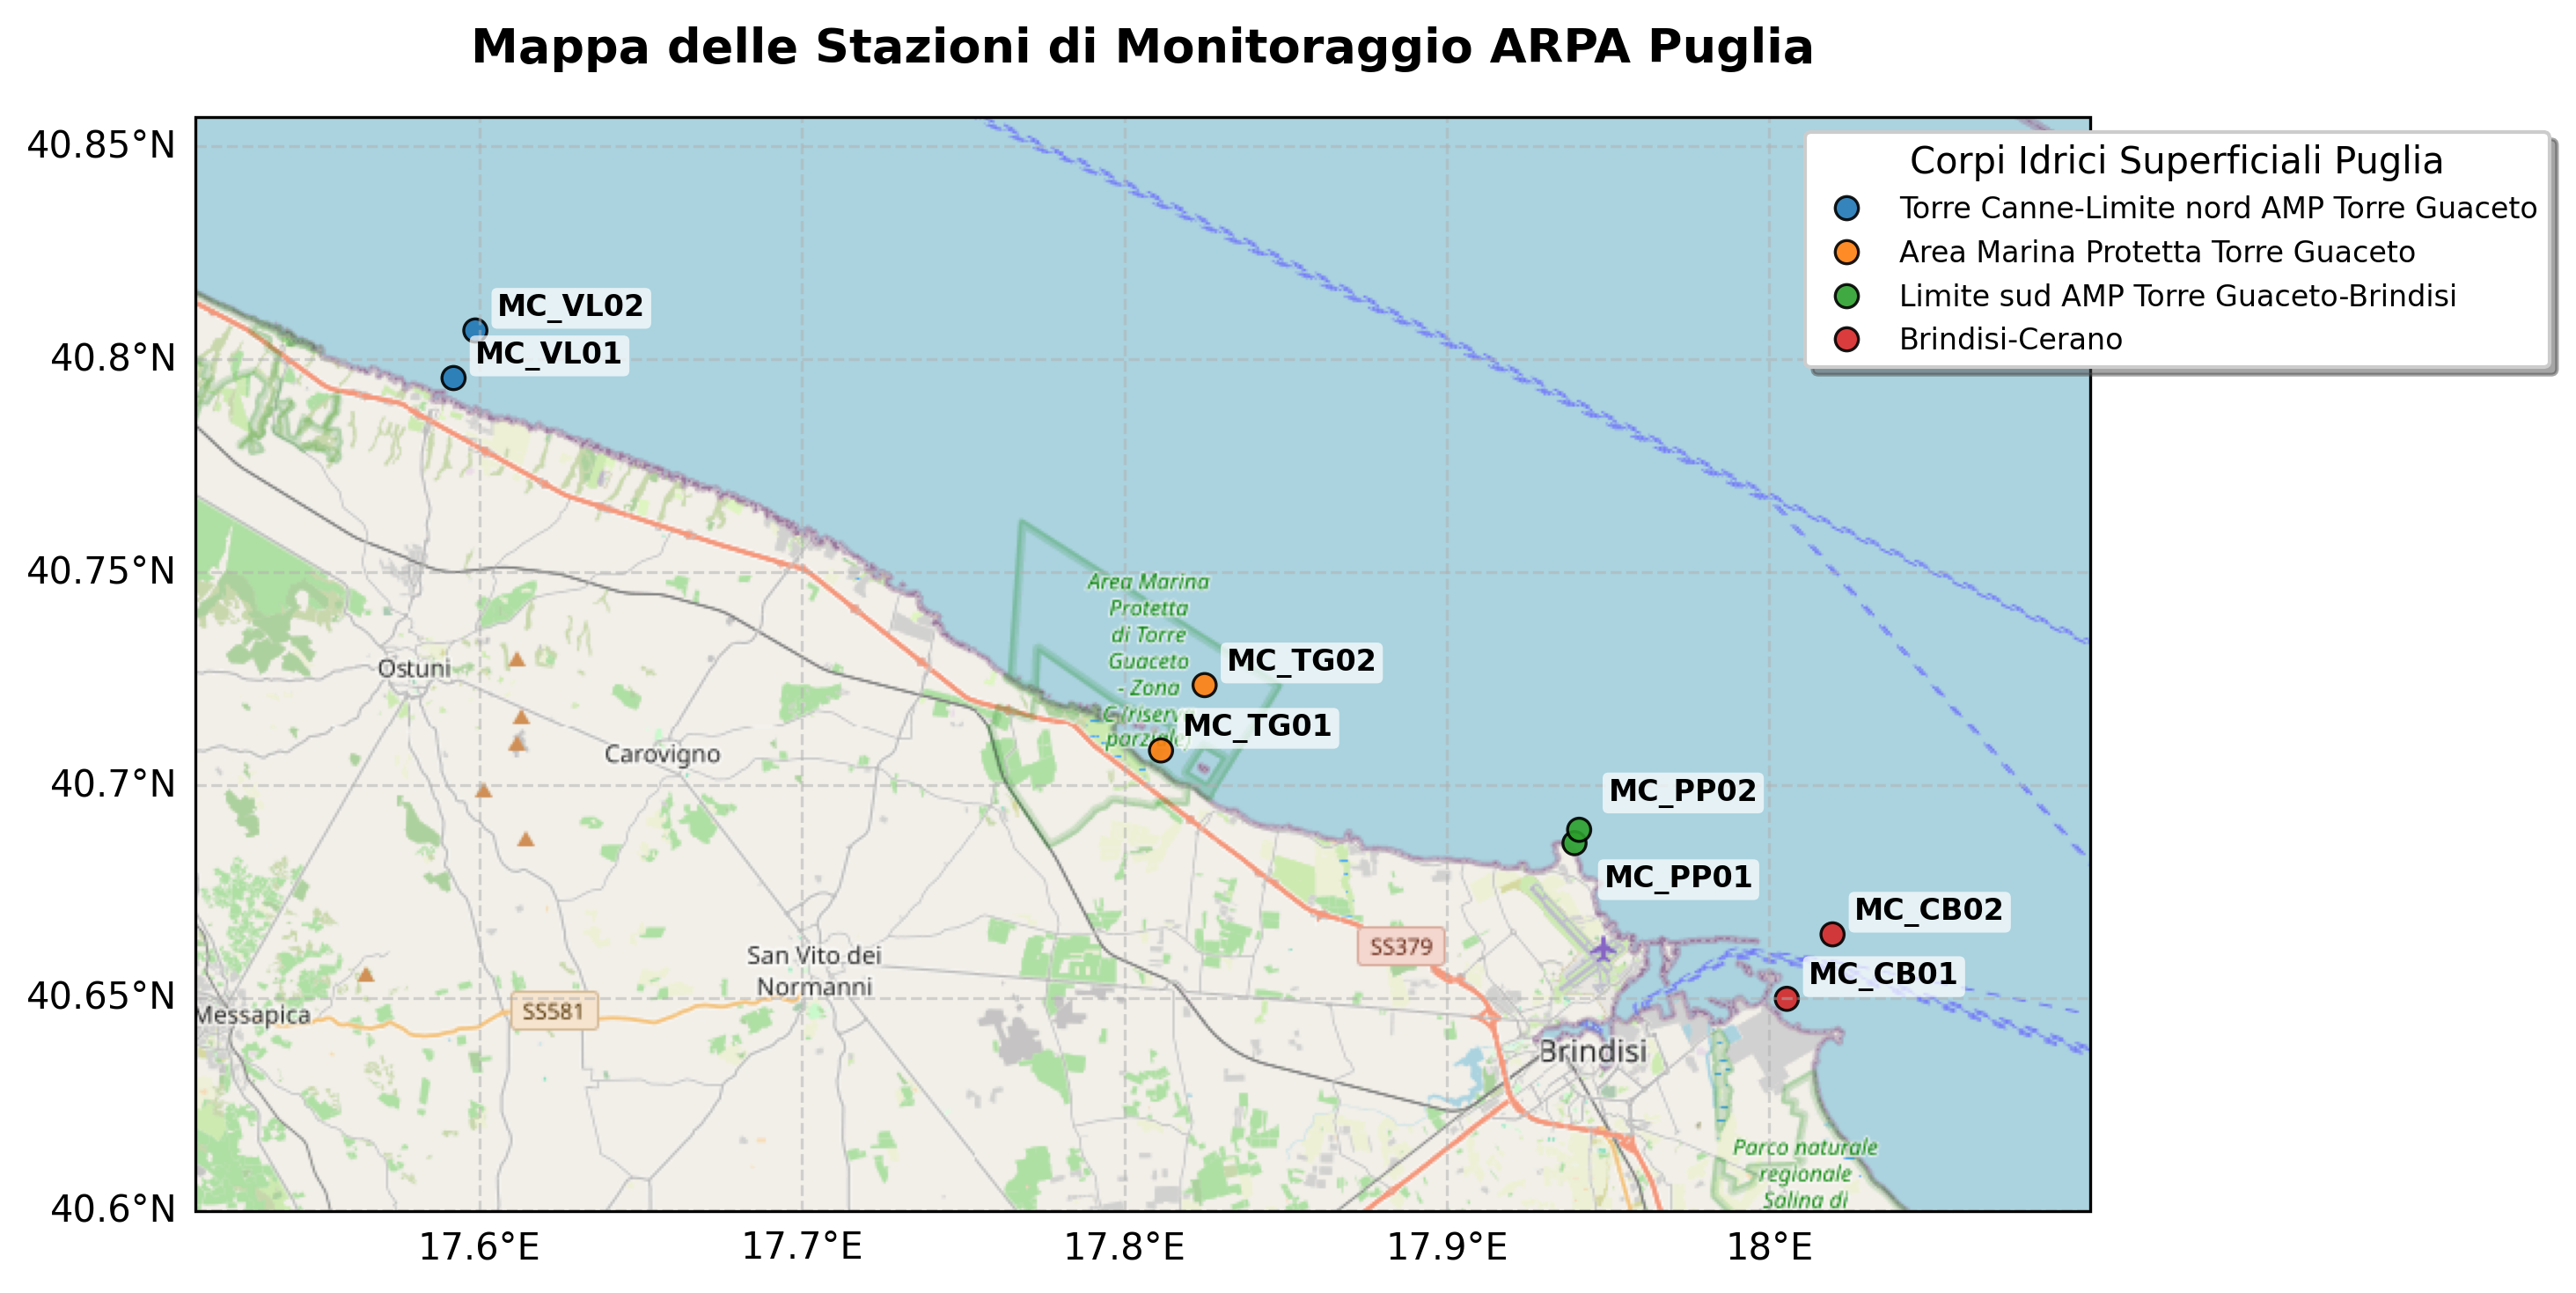

In [38]:

# Scarichiamo le immagini di sfondo da OpenStreetMap 
osm_sfondo = cti.OSM()    #OSM = OpenStreetMap = è un provider = servizio web che fornisce le immagini cartografiche) 
                          #cti.OSM() è una funzione che fa sì che Python si colleghi al provider OSM per scaricare i riquadri di mappa corrispondenti alle zone del grafico per poi usarli come sfondo 

# Creiamo la figura usando la proiezione specifica del provider di mappe (osm_sfondo.crs)
fig, ax = plt.subplots(
    figsize=(10, 7), 
    dpi=300, 
    subplot_kw={'projection': osm_sfondo.crs} #le mappe Web non usano la classica griglia di gradi (plateCarrree()) ma una proiezione proiettata: Web Mercator (EPSG:3857) che permette di visualizzare le coordinate geografiche in gradi decimali (latitudine e longitudine) in modo corretto sulla mappa
)   #inserendo osm_sfondo.crs come proiezione, il grafico sarà allineato correttamente con le immagini di sfondo scaricate da OpenStreetMap

#Impostiamo lo zoom dell'area con un piccolo margine (0.08 sull'asse x e 0.05 sull'asse y) attorno ai punti decimali
    #a) definisco i valori min e max 
min_long, max_long = df_cis['LONG_DD'].min() - 0.08, df_cis['LONG_DD'].max() + 0.08
min_lat, max_lat = df_cis['LAT_DD'].min() - 0.05, df_cis['LAT_DD'].max() + 0.05
    #b) ax.set_extent() imposta i limiti della mappa    #crsc=ccrs.PlateCarree() indica che le coordinate scritte nelle parentesi [] sono in gradi decimali (lat e long)
ax.set_extent([min_long, max_long, min_lat, max_lat], crs=ccrs.PlateCarree())

# Aggiungiamo lo sfondo fotografico/cartografico 
    #ax.add_image() aggiunge le immagini scaricate (osm_sfondo) e le mette come sfondo
ax.add_image(osm_sfondo, 11)   #11 = zoom level = livello di dettaglio dell'immagine (valori tra 10 e 12 sono adatti x una mappa a scala regionale/provnciale)

# Disegniamo le stazioni con lo scatterplot di Seaborn
sns.scatterplot(
    data=df_cis, 
    x='LONG_DD', 
    y='LAT_DD', 
    hue='Corpo_idrico', 
    s=40, 
    alpha=0.9, 
    edgecolor='black',  # Bordo nero ai punti per farli risaltare sullo sfondo
    linewidth=0.8,
    ax=ax,
    transform=ccrs.PlateCarree() #ccrs.PlateCarree() dice a Cartopy di proiettare i dati in gradi decimali 
)

# Etichette gestite per evitare sovrapposizioni nei punti vicini
for idx, row in df_cis.iterrows():
    stazione = row['Code_staz']
    if stazione == 'MC_PP02':
        offset = (8, 8)
    elif stazione == 'MC_PP01':
        offset = (8, -12)
    else:
        offset = (6, 4)
        
    ax.annotate(   #ax.annoatate() aggiunge un'etichetta
        stazione,  #stazione è il testo dell'etichetta
        (row['LONG_DD'], row['LAT_DD']),   #coordinata del punto a cui è associata
        xytext=offset, #xytext=offset = spostamento dell'etichetta rispetto al punto (in pixel)
        textcoords="offset points", #textcoords="offset points" indica che le coordinate dell'etichetta sono relative al punto
        ha='left', #ha='left' allinea il testo a sinistra del punto
        fontsize=8, 
        fontweight='bold',     #bbox=dict() crea un rettangolo bianco semitrasparente attorno al testo dell'etichetta (x migliorarne la leggibilità)
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7), # Sfondo bianco semitrasparente al testo
        transform=ccrs.PlateCarree()  #boxstyle="round" crea un box con gli angoli arrotondati e "pad=0.2" aggiunge un po' di spazio tra il testo e il bordo del box
    )  #transform=ccrs.PlateCarree() indica che le coordinate dei punti sono in gradi decimali (lat e long)

#Titolo e Legenda                                                                 #pad è lo spazio tra il titolo e il grafico
plt.title('Mappa delle Stazioni di Monitoraggio ARPA Puglia', fontsize=13, fontweight='bold', pad=15) 

#gl = griglia   #ax.gridlines() crea una giglia    #draw_labels=True disegna le etichette dei gradi sugli assi della mappa   #linestyle='--' imposta il tratteggio della griglia   
gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.5)
gl.top_labels = False  # Nasconde le etichette della griglia sul bordo superiore
gl.right_labels = False  # Nasconde le etichette della griglia sul bordo destro

plt.legend(
    title='Corpi Idrici Superficiali Puglia', 
    title_fontsize=10, 
    fontsize=8, 
    loc='upper right', 
    bbox_to_anchor=(1.25, 1),  #box_to_anchor = box della legenda spostato a dx 
    frameon=True,  #frameon=True disegna il bordo della legenda
    shadow=True    #aggiunge un'ombra alla legenda
)

plt.tight_layout() 
plt.show()

#### Ora creiamo in modo analogo la cartina per l'altra rete di monitoraggio

In [39]:
#carichiamo il file con le misure di densità di Ostreopsis ovata in Puglia dal 2014 al 2023
path=r'C:\\Users\\sofia\\Università\\Tirocinio\\Dati ARPA\\Arpa_Puglia_dataset\\Dataset_Ostreopsis-Aliena_2014-2023.xlsx'
df= pd.read_excel(path, header=2, sheet_name=1)
df_ost = df

#visualizziamo i dati 
display(df)

,ANNO,Data,PROVINCIA,SITO,QUOTA,Densità Ostreopsis ovata (cell/L),Unnamed: 6,Unnamed: 7,Unnamed: 8,Unnamed: 9
0,2014,2014-06-13,BR,APANI LIDO S.VINCENZO (BR),Acque fondo,500,NaN,NaN,NaN,
1,2014,2014-06-13,BR,APANI LIDO S.VINCENZO (BR),Acque colonna,320,NaN,NaN,NaN,NaN
2,2014,2014-06-26,BR,APANI LIDO S.VINCENZO (BR),Acque fondo,200,NaN,NaN,NaN,NaN
3,2014,2014-06-26,BR,APANI LIDO S.VINCENZO (BR),Acque colonna,120,NaN,NaN,NaN,NaN
4,2014,2014-07-10,BR,APANI LIDO S.VINCENZO (BR),Acque fondo,400,NaN,NaN,NaN,NaN
...,...,...,...,...,...,...,...,...,...,...
475,2023,2023-08-17,BR,TORRE CANNE DI FRONTE AL FARO (BR),Acque colonna,79,NaN,NaN,NaN,NaN
476,2023,2023-09-12,BR,TORRE CANNE DI FRONTE AL FARO (BR),Acque fondo,3611,NaN,NaN,NaN,NaN
477,2023,2023-09-12,BR,TORRE CANNE DI FRONTE AL FARO (BR),Acque colonna,0,NaN,NaN,NaN,NaN
478,2023,2023-09-22,BR,TORRE CANNE DI FRONTE AL FARO (BR),Acque fondo,152251,NaN,NaN,NaN,NaN


In [40]:
#ora visualizziamo dove sono localizzati i siti di monitoraggio 

#creiamo il dataframe con le coordinate geografiche dei siti di monitoraggio
df_sites= pd.read_excel(path, header=2, sheet_name=0)
display(df_sites)

print(df_sites.columns)

,NOME SITO,PROVINCIA,COMUNE,N_wgs84,E_wgs84,X_utm33,Y_UTM33
0,LA FORCATELLA PRIMA CASA BIANCA (BR),BR,Fasano,40.8548,17.4456,706136.8437,4.525513e+06
1,TORRE CANNE DI FRONTE AL FARO (BR),BR,Fasano,40.8419,17.4711,708330.1535,4.524146e+06
2,APANI LIDO S.VINCENZO (BR),BR,Brindisi,40.6962,17.8278,738929.5286,4.508880e+06


Index(['NOME SITO', 'PROVINCIA', 'COMUNE', 'N_wgs84', 'E_wgs84', 'X_utm33',
       'Y_UTM33'],
      dtype='str')


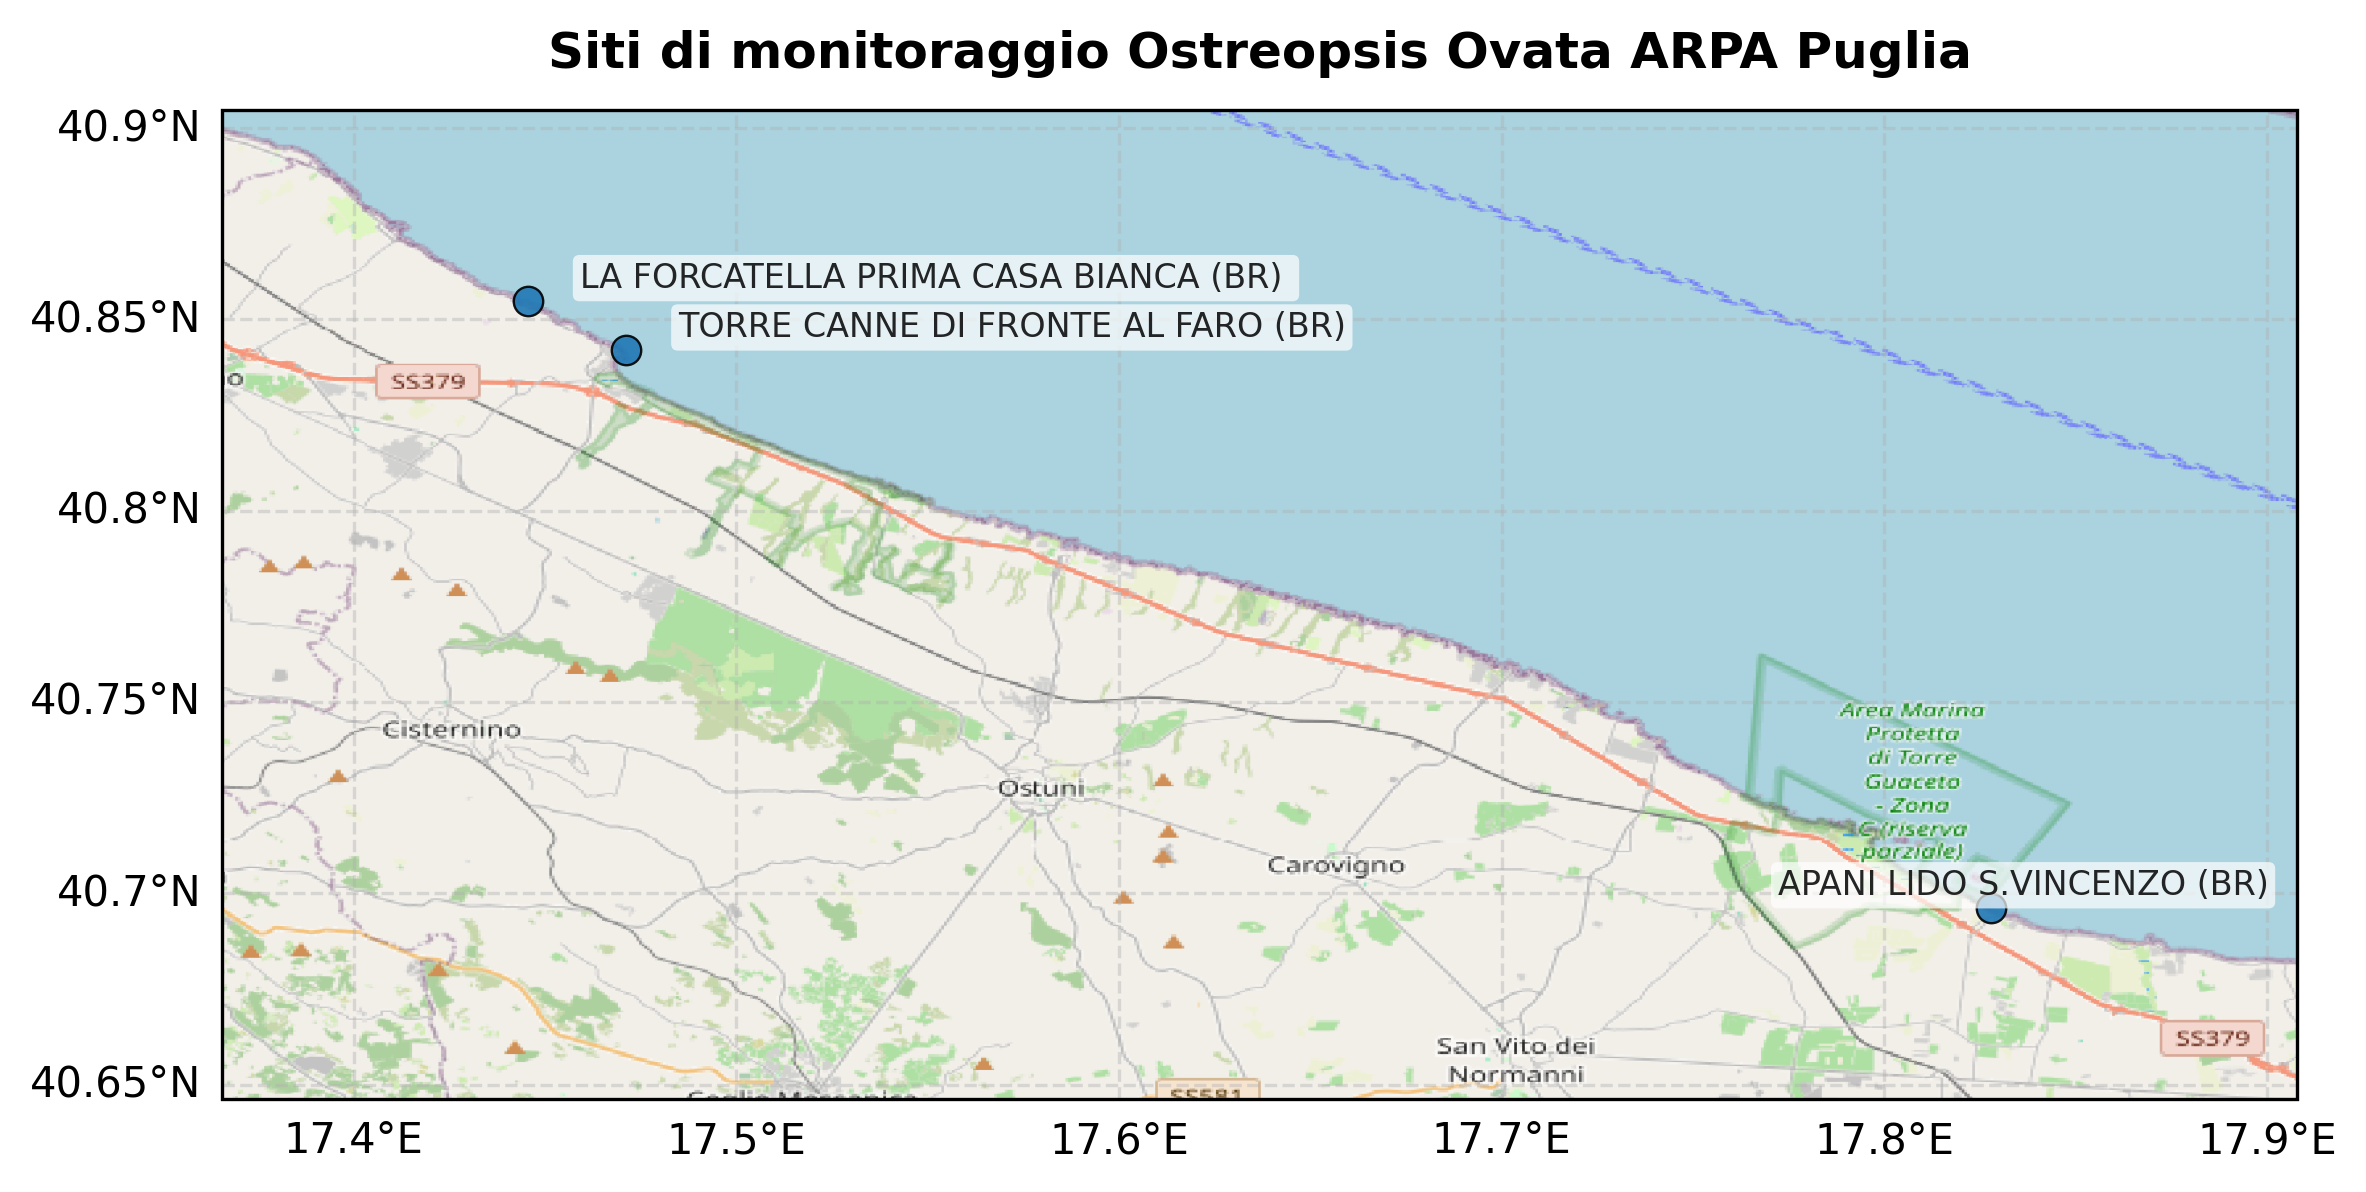

In [41]:
#definiamo lo sfondo (Open Street Map)
osm_title=cti.OSM()


#creiamo la figura e l'asse con proiezione geografica PlateCarree
fig, ax = plt.subplots(figsize=(8, 5), dpi=300, subplot_kw={'projection': ccrs.PlateCarree()})

#imposta il colore del fondo della mappa (azzurro per il mare)
ax.set_facecolor('#e0f2fe')

#definiamo i limiti della mappa (latitudine e longitudine)
margin_long, margin_lat = 0.08, 0.05
min_long=df_sites['E_wgs84'].min() - margin_long
max_long=df_sites['E_wgs84'].max() + margin_long
min_lat=df_sites['N_wgs84'].min() - margin_lat
max_lat=df_sites['N_wgs84'].max() + margin_lat
ax.set_extent([min_long, max_long, min_lat, max_lat], crs=ccrs.PlateCarree())

#aggiungiamo lo sfondo Open Street Map
ax.add_image(osm_title, 11)  #11 è il livello di zoom (da 0 a 19)

#disegniamo i punti di monitoraggio sulla mappa
sns.scatterplot(data=df_sites, x=df_sites['E_wgs84'],y=df_sites['N_wgs84'], s=50, edgecolor='black', alpha=0.9, ax=ax, transform=ccrs.PlateCarree())
texts= [] #creiamo una lista vuota per raccogliere le etichette da spostare
            #ciclo che scorre la tabella riga per riga (idx è l'indice della riga, row è la riga stessa)
            #puoi accedere ai valori con row['nome colonna'])
for idx, row in df_sites.iterrows():
    stazione = row['NOME SITO'] # assegna alla variabile stazione il valore della colonna 'NOME SITO' per la riga corrente
    t = ax.text(row['E_wgs84'], row['N_wgs84'], stazione, fontsize=8, bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7), # Sfondo bianco semitrasparente al testo
                alpha=0.85, transform = ccrs.PlateCarree())
            #t è la nuova variabile che contiene l'etichetta creata con ax.text()
            #ax.text() aggiunge un'etichetta al grafico
            #stazione è il testo dell'etichetta
            #(row['LONG_DD'], row['LAT_DD']) sono le coordinate del punto a cui associare l'etichetta
            #transform=ccrs.PlateCarree() indica che le coordinate dei punti sono in gradi decimali (lat e long)
    texts.append(t) #prende l'etichetta creata (t) e la aggiunge alla lista texts=[]

#subito dopo il ciclo il comando adjust_text() prende la lista di etichette e le sposta nei punti liberi migliori
adjust_text(texts, ax=ax)
plt.title('Siti di monitoraggio Ostreopsis Ovata ARPA Puglia', fontsize=12, fontweight='bold', pad=10)

#reticolato coi gradi
gl = ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4)
gl.top_labels=False
gl.right_labels=False


plt.tight_layout()
plt.show()

### Mappiamo le due reti di monitoraggio 

Mostriamo la vicinanza geografica esistente tra le stazioni appartenenti alle due reti di monitoraggio 

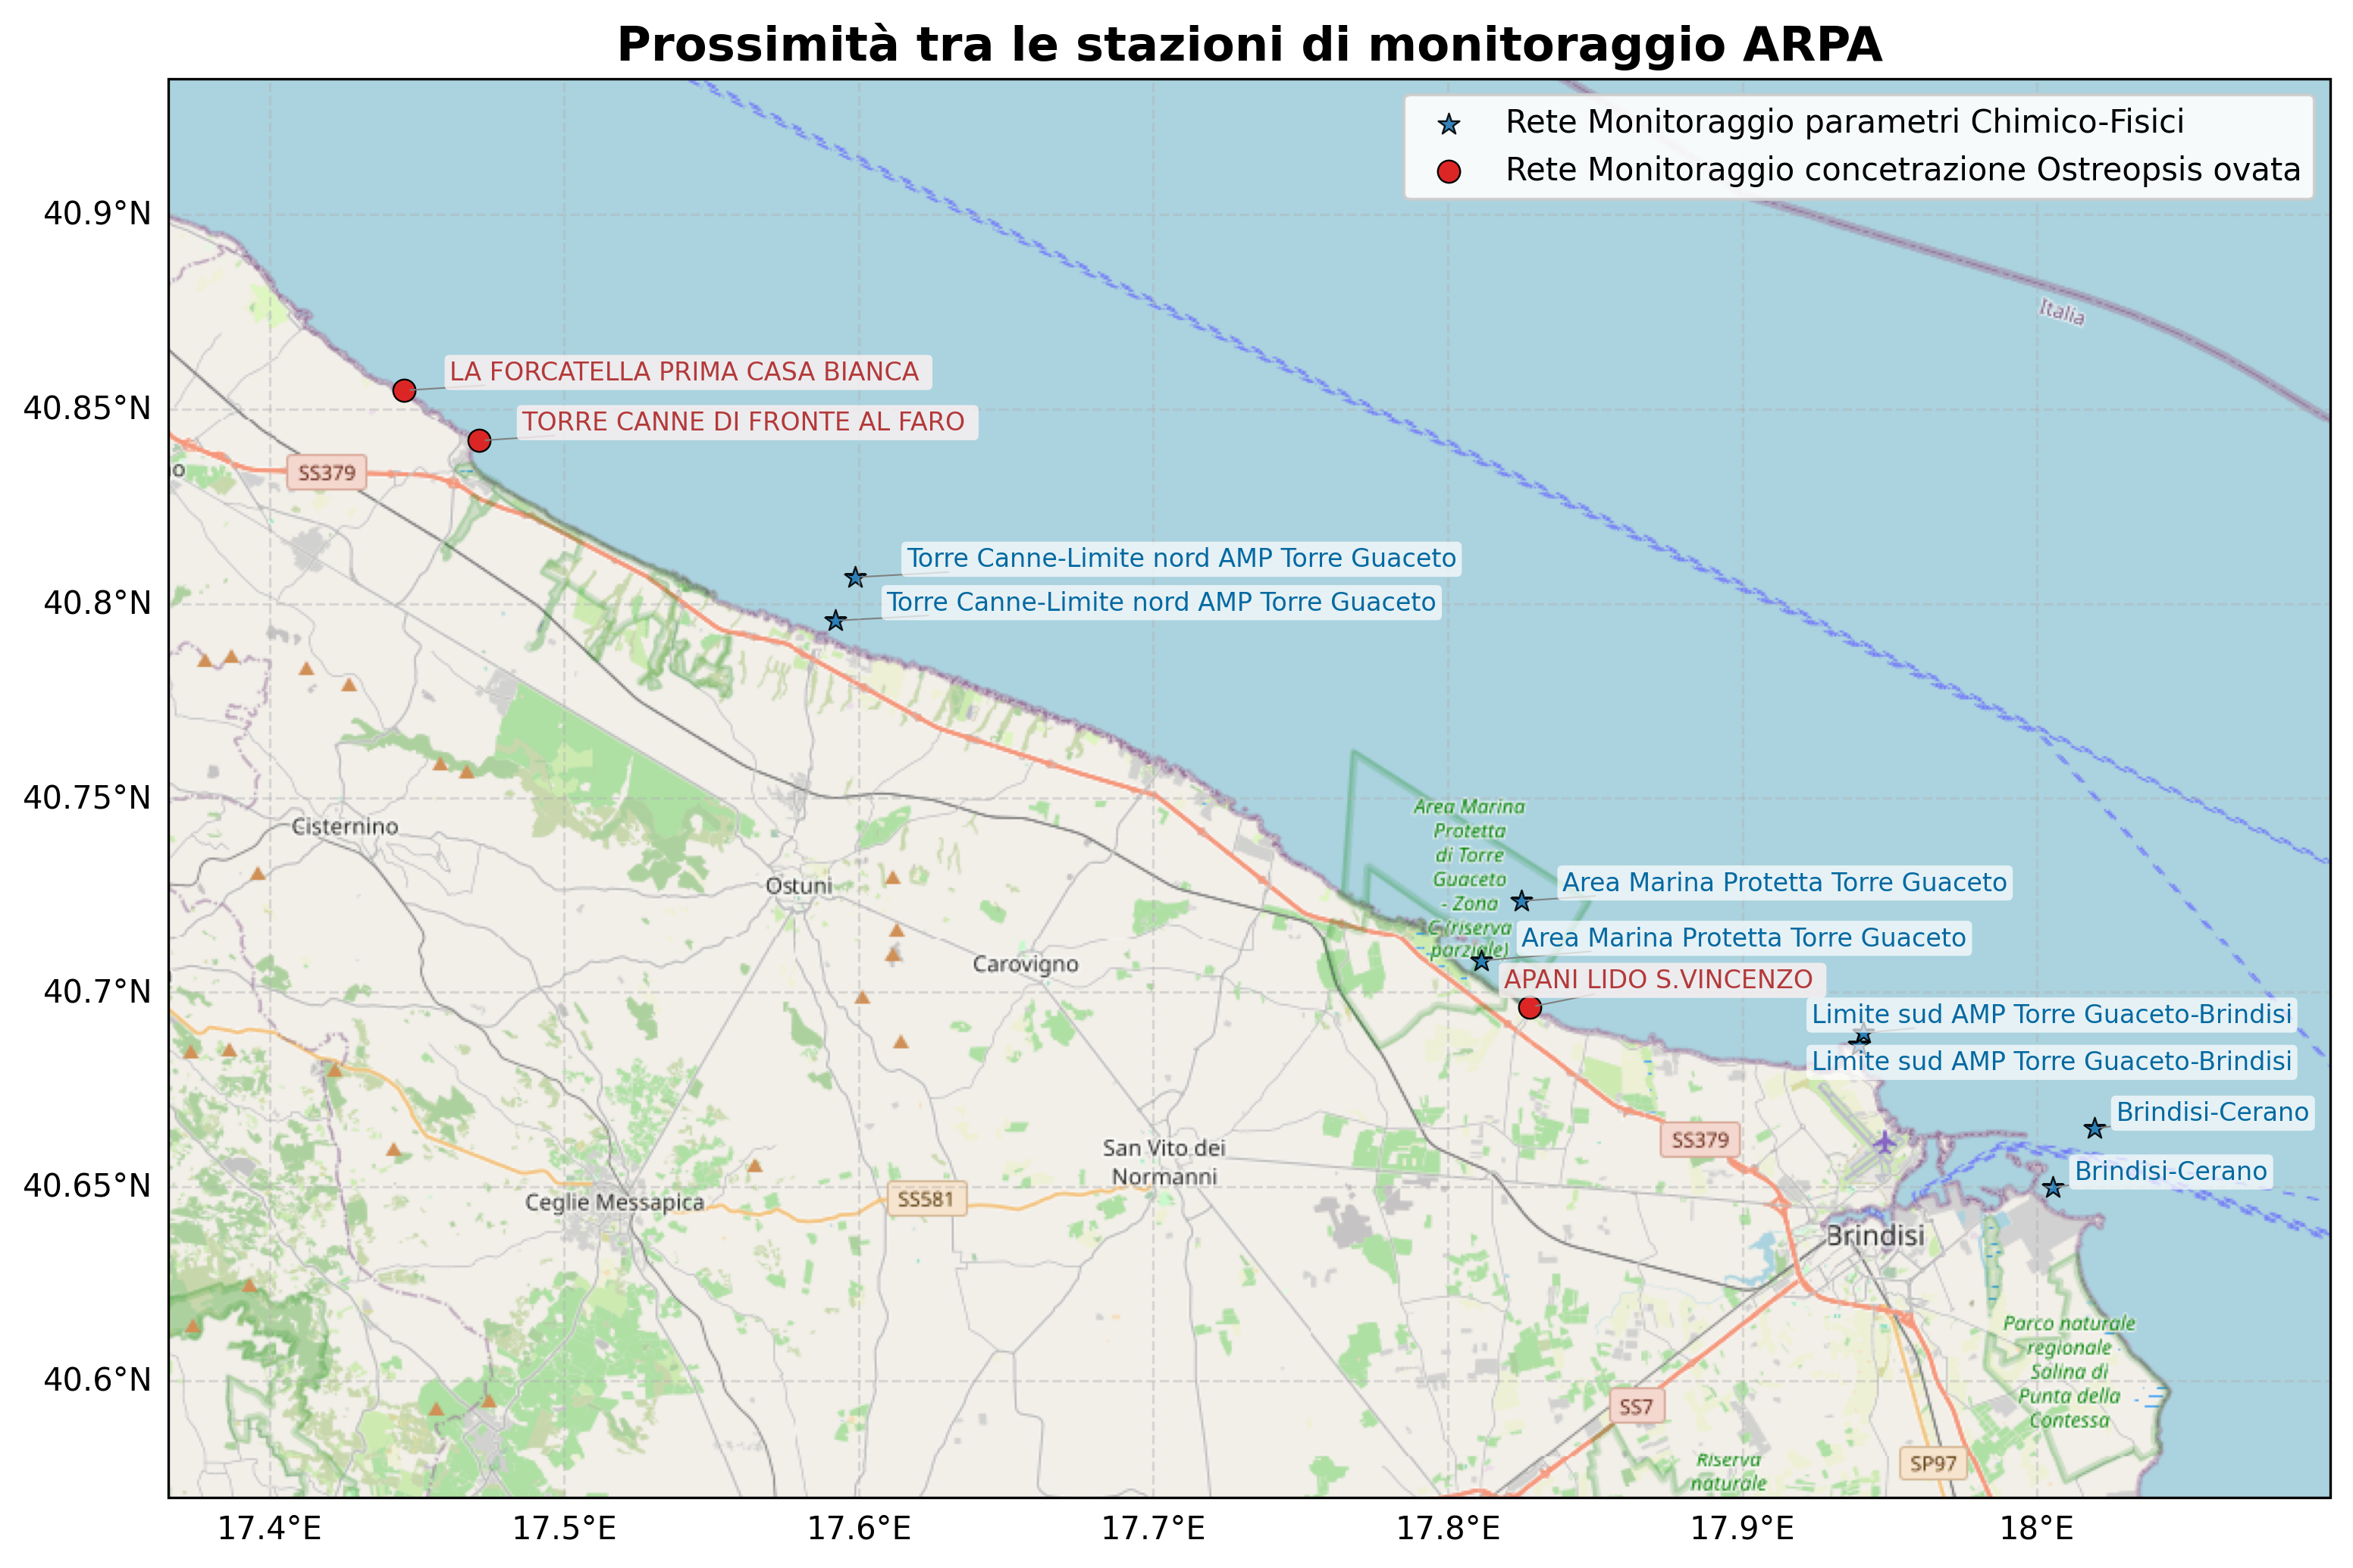

In [47]:
#creazione sfondo 
sfondo = cti.OSM()
fig, ax = plt.subplots(figsize=(11,7), dpi=300, subplot_kw={'projection': sfondo.crs})


#definiamo i limiti della mappa
min_long = min(df_cis['LONG_DD'].min(), df_sites['E_wgs84'].min()) - 0.08
max_long = max(df_cis['LONG_DD'].max(), df_sites['E_wgs84'].max()) + 0.08
min_lat = min(df_cis['LAT_DD'].min(), df_sites['N_wgs84'].min()) - 0.08
max_lat = max(df_cis['LAT_DD'].max(), df_sites['N_wgs84'].max()) + 0.08

ax.set_extent([min_long, max_long, min_lat, max_lat], crs=ccrs.PlateCarree())
ax.add_image(sfondo,11)

#disegnamo i punti rete CIS
sns.scatterplot(
    data=df_cis, x=df_cis['LONG_DD'], y=df_cis['LAT_DD'], 
    s=50, marker='*', edgecolor='black', alpha=0.9, ax=ax, 
    transform=ccrs.PlateCarree(), 
    label='Rete Monitoraggio parametri Chimico-Fisici'
    )
# tracciamo i pinti della rete Ost
sns.scatterplot(data=df_sites, x=df_sites['E_wgs84'],y=df_sites['N_wgs84'], 
                color='#dc2626', s=50, marker='o', edgecolor='black', ax=ax, 
                transform=ccrs.PlateCarree(), label='Rete Monitoraggio concetrazione Ostreopsis ovata'
                )

#etichette 
texts=[]
for _,row in df_cis.iterrows():
    t= ax.text(
        row['LONG_DD'], row['LAT_DD'], row['Corpo_idrico'], 
        fontsize=8, color='#0369a1', 
        bbox=dict(boxstyle="round,pad=0.2", fc="white", ec="none", alpha=0.7), 
        transform=ccrs.PlateCarree()
        )
    texts.append(t)
for _, row in df_sites.iterrows():
    name = row['NOME SITO'].split('(')[0]
    t = ax.text(
        row['E_wgs84'], row['N_wgs84'], name, 
        fontsize=8, color="#b43939", 
        bbox=dict(boxstyle="round,pad=0.2", fc="#fef2f2", ec="none", alpha=0.8),
        transform=ccrs.PlateCarree()
        )
    texts.append(t)
adjust_text(texts, ax=ax, arrowprops=dict(arrowstyle='-', color='gray', lw=0.5))


plt.title('Prossimità tra le stazioni di monitoraggio ARPA', fontsize=15, fontweight='bold')
gl=ax.gridlines(draw_labels=True, linestyle='--', alpha=0.4)
gl.top_labels =False
gl.right_labels=False

plt.legend(frameon=True, facecolor='white', framealpha=0.9)
plt.tight_layout()
plt.show()